# Lab 1 — Intro to Behavioral TV Data

# Name: Barsukov Artur | Group: KM-42


## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

c:\All worksapce\davi\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


We're checking to see if all the data has been loaded

In [2]:
for name, df in [("programs", programs), ("viewings", viewings),
                 ("daily_weights", daily_weights),
                 ("viewer_attributes", viewer_attributes),
                 ("attributes", attributes)]:
    print(name, df.shape)

programs (5841, 15)
viewings (1001885, 9)
daily_weights (407561, 4)
viewer_attributes (104679, 3)
attributes (58, 5)


## Task 1.1 — Panel and universe

In [3]:
hh = daily_weights[daily_weights["resp_type"] == "H"]
pp = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]

print("Telecasts:", programs["telecast_id"].nunique())
print("Programs:", programs["program_name"].nunique())
print("Networks:", programs["network_name"].nunique())
print("Households in panel:", hh["respondent_id"].nunique())
print("Persons in panel:", pp["respondent_id"].nunique())
print("Households in-tab, average day:", round(hh.groupby("broadcast_date")["respondent_id"].nunique().mean()))
print("Persons in-tab, average day:", round(pp.groupby("broadcast_date")["respondent_id"].nunique().mean()))
print("US TV households represented, average day (M):", round(hh.groupby("broadcast_date")["weight"].sum().mean() / 1000000, 2))
print("US persons represented, average day (M):", round(pp.groupby("broadcast_date")["weight"].sum().mean() / 1000000, 2))

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


**1. Panel and universe.** The programs table has 5,841 telecasts, 246 distinct programs and 10 networks. In October 4,254 households and 10,210 persons were in-tab at least once. On an average day about 3,878 households and 9,269 persons are in-tab, and their weights add up to 125.80 million US TV households and 317.28 million US persons, which matches the universe. viewer_attributes lists a few more respondents because it describes everyone who belongs to the panel, while daily_weights contains only respondents who were measured on at least one broadcast day of October.

## Task 1.2 — Average audience by hour of day

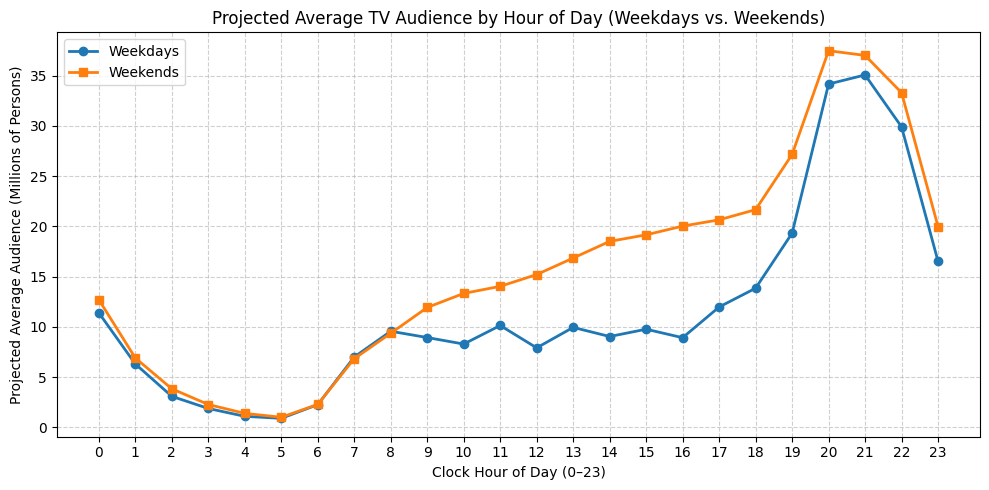

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [4]:
average_audience = viewings[viewings["resp_type"].isin(["R", "L"])][["start_ts", "end_ts", "weight"]].reset_index(drop=True)

ts = pd.Timedelta(hours=6)

broadcast_ts = average_audience["start_ts"] - ts

average_audience["broadcast_date"] = broadcast_ts.dt.date

average_audience["day_type"] = np.where(broadcast_ts.dt.dayofweek < 5, "weekday", "weekend") # np.where() векторний if-else 

base_day = average_audience["start_ts"].dt.floor("D")

start_min = (average_audience["start_ts"] - base_day ).dt.total_seconds() / 60 
end_min = (average_audience["end_ts"] - base_day).dt.total_seconds() / 60 

days_count = average_audience.groupby("day_type")["broadcast_date"].nunique()

hourly_stats = []
for h in range(0, 24):
    h_start = h * 60
    h_end = (h + 1) * 60    
    overlap_day1 = (np.minimum(end_min, h_end) - np.maximum(start_min, h_start)).clip(lower=0)
    overlap_day2 = (np.minimum(end_min, h_end + 1440) - np.maximum(start_min, h_start + 1440)).clip(lower=0)
    mins_in_hour = overlap_day1 + overlap_day2

    average_audience["weighted_mins"] = mins_in_hour * average_audience["weight"]
    
    grouped_sums = average_audience.groupby("day_type")["weighted_mins"].sum()
    
    avg_aud = grouped_sums / (60 * days_count) / 1e6
    
    hourly_stats.append({
        "hour": h,
        "weekday": avg_aud.get("weekday", 0),
        "weekend": avg_aud.get("weekend", 0)
    })

hourly_df = pd.DataFrame(hourly_stats).set_index("hour")

plt.figure(figsize=(10, 5))
plt.plot(hourly_df.index, hourly_df["weekday"], marker="o", linewidth=2, label="Weekdays")
plt.plot(hourly_df.index, hourly_df["weekend"], marker="s", linewidth=2, label="Weekends")
plt.xticks(range(0, 24))
plt.xlabel("Clock Hour of Day (0–23)")
plt.ylabel("Projected Average Audience (Millions of Persons)")
plt.title("Projected Average TV Audience by Hour of Day (Weekdays vs. Weekends)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

peak_hour_weekday = hourly_df["weekday"].idxmax()
peak_hour_weekend = hourly_df["weekend"].idxmax()

print(f"Peak hour, weekdays: {peak_hour_weekday}")
print(f"Peak hour, weekends: {peak_hour_weekend}")


**Answer:** how the weekend differs.

On both weekdays and weekends, viewership peaks during the evening “prime time” (around 8:00–9:00 p.m.). However, on weekends, viewership is significantly higher in the morning and afternoon (roughly from 9:00 a.m. to 5:00 p.m.), since people are not at work or school and are more likely to watch daytime shows or live sports broadcasts.

 ## Task 1.3 — Session length

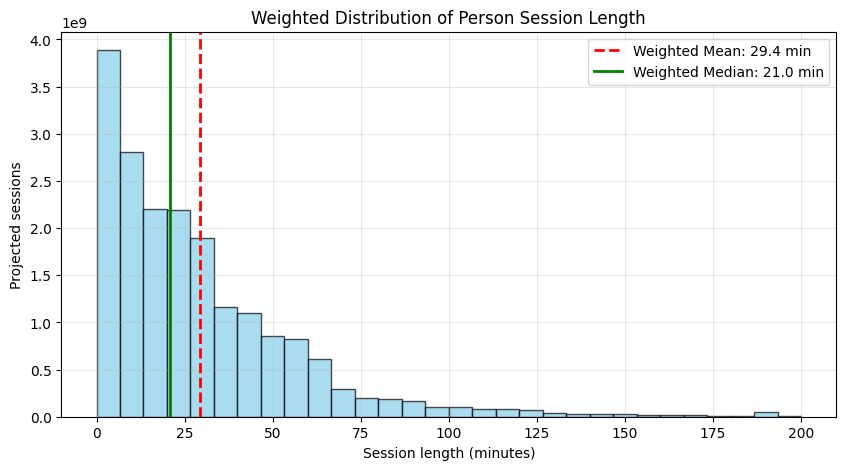

Session length, weighted mean (min): 29.37
Session length, weighted median (min): 21.0


In [5]:
session_leng = viewings[viewings["resp_type"].isin(["R", "L"])][["start_ts", "end_ts", "weight"]].reset_index(drop=True)

session_leng["length_of_watchmin"] = (session_leng["end_ts"] - session_leng["start_ts"]).dt.total_seconds() / 60

weighted_mean = np.average(session_leng["length_of_watchmin"], weights=session_leng["weight"])

weighted_median = session_leng.sort_values(by="length_of_watchmin")
weighted_median["cumsum"] = weighted_median["weight"].cumsum()
half_weight = weighted_median["weight"].sum() / 2
weighted_median = weighted_median.loc[weighted_median["cumsum"] >= half_weight, "length_of_watchmin"].values[0]

plt.figure(figsize=(10, 5))

plt.hist(session_leng["length_of_watchmin"], weights=session_leng["weight"], bins=30, range=(0, 200), color='skyblue', edgecolor='black', alpha=0.7)

plt.axvline(weighted_mean, color='red', linestyle='--', linewidth=2, label=f'Weighted Mean: {weighted_mean:.1f} min')
plt.axvline(weighted_median, color='green', linestyle='-', linewidth=2, label=f'Weighted Median: {weighted_median:.1f} min')

plt.xlabel("Session length (minutes)")
plt.ylabel("Projected sessions")
plt.title("Weighted Distribution of Person Session Length")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Session length, weighted mean (min):", round(weighted_mean, 2))
print("Session length, weighted median (min):", weighted_median)


**Answer:** why mean and median differ; which one you would show a client.

The distribution exhibits strong right-skewed asymmetry, with a high concentration of short sessions at the beginning and a long tail of very long sessions on the right. Due to this wide range, the weighted average is heavily skewed upward by extreme outliers and does not reflect the typical session duration. The weighted median provides a much more accurate picture of typical viewing behavior. For a client presentation, I would highlight the weighted median as the most reliable metric, but I would also show the mean and the full distribution graph to provide complete context.

## Task 2 — Program reach curve


Table: Ratings and Projected Audience per Telecast


,broadcast_date,start_ts,household_rating,p2_rating,projected_audience_m
1108,2024-10-01,2024-10-01 18:30:00,3.469247,1.665405,5.283950
1128,2024-10-02,2024-10-02 18:30:00,3.066619,1.476228,4.683736
1148,2024-10-03,2024-10-03 18:30:00,2.991061,1.474863,4.679414
1167,2024-10-04,2024-10-04 18:30:00,2.997439,1.514643,4.805626
1207,2024-10-07,2024-10-07 18:30:00,3.061468,1.523255,4.832950
1223,2024-10-08,2024-10-08 18:30:00,3.169327,1.565220,4.966096
1241,2024-10-09,2024-10-09 18:30:00,2.979151,1.481501,4.700478
1256,2024-10-10,2024-10-10 18:30:00,3.382224,1.618421,5.134898
1272,2024-10-11,2024-10-11 18:30:00,3.085087,1.476923,4.685951
1311,2024-10-14,2024-10-14 18:30:00,2.934769,1.446106,4.588172



Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


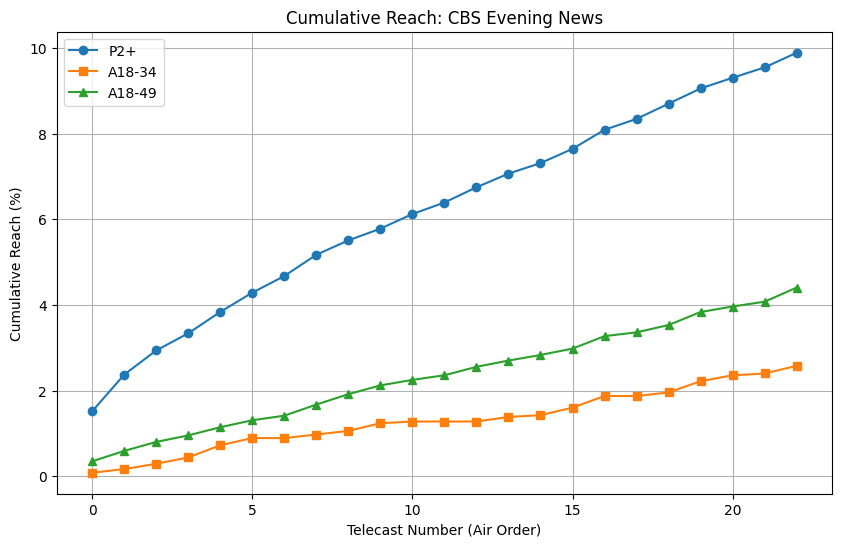

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

cbs = programs[programs["program_name"] == "CBS Evening News"].copy()
cbs["broadcast_date"] = pd.to_datetime(cbs["broadcast_date"])
cbs = cbs[cbs["broadcast_date"].dt.dayofweek <= 4].sort_values(by="start_ts")

vie = viewings[viewings["resp_type"].isin(["H","R","L"]) & viewings["network_code"].isin(["CBS"])]

viewer_age = viewer_attributes[viewer_attributes["attr_id"] == 300]
viewer_age = viewer_age[["respondent_id", "value"]]

all_info = pd.merge(vie, viewer_age, on='respondent_id', how='left')

daily_weights['broadcast_date'] = pd.to_datetime(daily_weights['broadcast_date'])
avg_aud = daily_weights.groupby("respondent_id")["weight"].mean().reset_index()
avg_weights_age = pd.merge(avg_aud, viewer_age, on="respondent_id", how="left")

universe_p2 = avg_weights_age[avg_weights_age["value"] >= 2]["weight"].sum()
universe_a18_34 = avg_weights_age[(avg_weights_age["value"] >= 18) & (avg_weights_age["value"] <= 34)]["weight"].sum()
universe_a18_49 = avg_weights_age[(avg_weights_age["value"] >= 18) & (avg_weights_age["value"] <= 49)]["weight"].sum()

res_dict = {
    "hh_ratings": [],
    "p2_ratings": [],
    "proj_audiences": [],
    "reach_p2": [],
    "reach_a18_34": [],
    "reach_a18_49": []
}

seen_p2 = set()
seen_a18_34 = set()
seen_a18_49 = set()

for _, row in cbs.iterrows():
    b_date = row["broadcast_date"]
    p_start = row["start_ts"]
    p_end = row["end_ts"]
    
    mask_time = (all_info["start_ts"] < p_end) & (all_info["end_ts"] > p_start)
    overlap_views = all_info[mask_time].copy()
    
    if not overlap_views.empty:
        overlap_views['o_start'] = overlap_views['start_ts'].clip(lower=p_start)
        overlap_views['o_end'] = overlap_views['end_ts'].clip(upper=p_end)
        overlap_views['overlap_mins'] = (overlap_views['o_end'] - overlap_views['o_start']).dt.total_seconds() / 60
        
        valid_views = overlap_views[overlap_views['overlap_mins'] >= 1.0]
        unique_viewers = valid_views.groupby(["respondent_id", "resp_type", "value"], dropna=False)["weight"].max().reset_index()
    else:
        unique_viewers = pd.DataFrame(columns=["respondent_id", "resp_type", "value", "weight"])

    daily_base = daily_weights[daily_weights["broadcast_date"] == b_date]
    hh_base = daily_base[daily_base["resp_type"] == "H"]["weight"].sum()
    
    p2_daily = pd.merge(daily_base[daily_base["resp_type"].isin(["R", "L"])], viewer_age, on="respondent_id", how="left")
    p2_base = p2_daily[p2_daily["value"] >= 2]["weight"].sum()


    hh_aud = unique_viewers[unique_viewers["resp_type"] == "H"]["weight"].sum()
    p2_aud = unique_viewers[(unique_viewers["resp_type"].isin(["R", "L"])) & (unique_viewers["value"] >= 2)]["weight"].sum()
    
    res_dict["hh_ratings"].append((hh_aud / hh_base * 100) if hh_base > 0 else 0)
    res_dict["p2_ratings"].append((p2_aud / p2_base * 100) if p2_base > 0 else 0)
    res_dict["proj_audiences"].append(p2_aud / 1_000_000) 

    curr_p2_ids = set(unique_viewers[(unique_viewers["resp_type"].isin(["R", "L"])) & (unique_viewers["value"] >= 2)]["respondent_id"])
    curr_a18_34_ids = set(unique_viewers[(unique_viewers["value"] >= 18) & (unique_viewers["value"] <= 34)]["respondent_id"])
    curr_a18_49_ids = set(unique_viewers[(unique_viewers["value"] >= 18) & (unique_viewers["value"] <= 49)]["respondent_id"])
    
    seen_p2.update(curr_p2_ids)
    seen_a18_34.update(curr_a18_34_ids)
    seen_a18_49.update(curr_a18_49_ids)
    
    reach_p2_weight = avg_weights_age[avg_weights_age["respondent_id"].isin(seen_p2)]["weight"].sum()
    reach_a18_34_weight = avg_weights_age[avg_weights_age["respondent_id"].isin(seen_a18_34)]["weight"].sum()
    reach_a18_49_weight = avg_weights_age[avg_weights_age["respondent_id"].isin(seen_a18_49)]["weight"].sum()
    
    res_dict["reach_p2"].append((reach_p2_weight / universe_p2 * 100) if universe_p2 > 0 else 0)
    res_dict["reach_a18_34"].append((reach_a18_34_weight / universe_a18_34 * 100) if universe_a18_34 > 0 else 0)
    res_dict["reach_a18_49"].append((reach_a18_49_weight / universe_a18_49 * 100) if universe_a18_49 > 0 else 0)


cbs['household_rating'] = res_dict["hh_ratings"]
cbs['p2_rating'] = res_dict["p2_ratings"]
cbs['projected_audience_m'] = res_dict["proj_audiences"]

print("Table: Ratings and Projected Audience per Telecast")
display(cbs[['broadcast_date', 'start_ts', 'household_rating', 'p2_rating', 'projected_audience_m']])

avg_hh_rating = sum(res_dict["hh_ratings"]) / len(res_dict["hh_ratings"])
avg_p2_rating = sum(res_dict["p2_ratings"]) / len(res_dict["p2_ratings"])
avg_proj_aud = sum(res_dict["proj_audiences"]) / len(res_dict["proj_audiences"])

print(f"\nTelecasts of the program: {len(cbs)}")
print(f"Average household rating (%): {avg_hh_rating:.1f}")
print(f"Average P2+ rating (%): {avg_p2_rating:.1f}")
print(f"Average projected audience (M): {avg_proj_aud:.2f}")
print(f"Final reach P2+ (%): {res_dict['reach_p2'][-1]:.1f}")
print(f"Final reach A18-34 (%): {res_dict['reach_a18_34'][-1]:.1f}")
print(f"Final reach A18-49 (%): {res_dict['reach_a18_49'][-1]:.1f}")

plt.figure(figsize=(10, 6))
plt.plot(res_dict["reach_p2"], label="P2+", marker='o')
plt.plot(res_dict["reach_a18_34"], label="A18-34", marker='s')
plt.plot(res_dict["reach_a18_49"], label="A18-49", marker='^')

plt.title("Cumulative Reach: CBS Evening News")
plt.xlabel("Telecast Number (Air Order)")
plt.ylabel("Cumulative Reach (%)")
plt.legend()
plt.grid(True)
plt.show()



**Answer:** reach vs rating; which audience is reached best, and why.

The cumulative "reach" keeps growing because each new "telecast" attracts some unique, first-time viewers over the month, continuously adding to the total unduplicated audience. At the same time, the individual "rating" stays roughly flat because the total number of simultaneous viewers watching on any single night remains relatively consistent.

The program reaches the "P2+" audience best, achieving a final "reach" of 9.9%, which is significantly higher than the 4.4% "reach" for "A18-49" and 2.6% for "A18-34". This matches standard viewership patterns, as network evening news typically skews heavily toward older demographics and captures a much smaller share of young adult audiences.


## Task 3 — Program frequency


In [7]:
def revers_in_min(column: pd.Series) -> pd.Series:
    hours = column.dt.hour
    minutes = column.dt.minute
    seconds = column.dt.second

    return (hours * 60) + minutes + (seconds / 60)

 
vie["start_ts"] = revers_in_min(column=vie["start_ts"])
vie["end_ts"] = revers_in_min(column=vie["end_ts"])


Projected viewers (M): 30.8
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


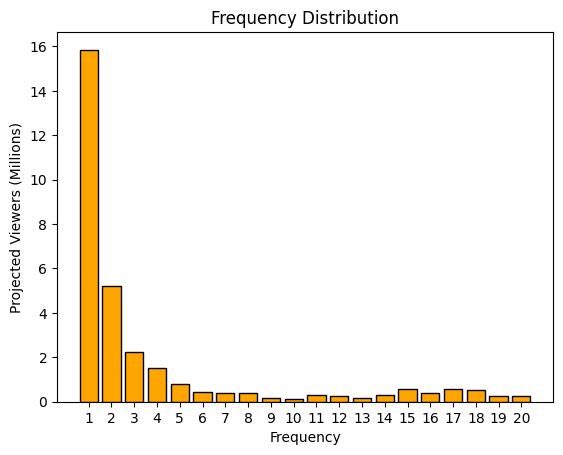

In [8]:

soap = programs[programs["program_name"] == "The Young and the Restless"]
vie = viewings[viewings["resp_type"].isin(["L", "R"]) & (viewings["network_code"] == "CBS")].copy()

check = soap.head(1)
pos1 = revers_in_min(check["start_ts"]).iloc[0]
pos2 = revers_in_min(check["end_ts"]).iloc[0]

soap_broadcast_dates = pd.to_datetime(soap["broadcast_date"]).dt.normalize()
vie = vie[vie["start_ts"].dt.normalize().isin(soap_broadcast_dates)]

vie["view_date"] = vie["start_ts"].dt.normalize()

vie["start_ts"] = revers_in_min(column=vie["start_ts"])
vie["end_ts"] = revers_in_min(column=vie["end_ts"])

valid_views = vie[
    (vie["start_ts"] < pos2) &  
    (vie["end_ts"] > pos1)    
].copy()

valid_views["actual_start"] = np.maximum(valid_views["start_ts"], pos1)
valid_views["actual_end"] = np.minimum(valid_views["end_ts"], pos2)
valid_views["watched_mins"] = valid_views["actual_end"] - valid_views["actual_start"]

valid_views = valid_views[valid_views["watched_mins"] >= 1]

freq_df = valid_views.groupby("respondent_id")["view_date"].nunique().reset_index(name="frequency")

monthly_weights = daily_weights.groupby("respondent_id")["weight"].mean().reset_index()

merged = pd.merge(freq_df, monthly_weights, on="respondent_id", how="inner")

projected_viewers_m = merged["weight"].sum() / 1_000_000
avg_freq = np.average(merged["frequency"], weights=merged["weight"])

merged = merged.sort_values("frequency")
merged["cum_weight"] = merged["weight"].cumsum()
total_weight = merged["weight"].sum()

median_freq = merged[merged["cum_weight"] >= total_weight * 0.5]["frequency"].iloc[0]
p80_freq = merged[merged["cum_weight"] >= total_weight * 0.8]["frequency"].iloc[0]

loyal_viewers = merged[merged["frequency"] >= p80_freq]
loyal_views = (loyal_viewers["frequency"] * loyal_viewers["weight"]).sum()
total_views = (merged["frequency"] * merged["weight"]).sum()
share_loyal = loyal_views / total_views

print("Projected viewers (M):", round(projected_viewers_m, 2))
print("Average frequency (weighted):", round(avg_freq, 2))
print("Median frequency (weighted):", median_freq)
print("Share of views from the most loyal viewers:", round(share_loyal, 3))

dist = merged.groupby("frequency")["weight"].sum() / 1_000_000
plt.bar(dist.index, dist.values, color='orange', edgecolor='black')
plt.xlabel("Frequency")
plt.ylabel("Projected Viewers (Millions)")
plt.title("Frequency Distribution")
plt.xticks(dist.index)
plt.show()

**Answer:** is the average frequency a fair summary?

The average "frequency" is not a representative or objective metric ("the average can lie") because the distribution of "views" is highly skewed. As the chart and calculations show, the vast majority of total "views" are generated by a narrow segment of the "most loyal viewers". At the same time, a massive number of people watched the series only 1 or 2 times a month. Because of this asymmetry, the median serves as a much more accurate indicator of a typical viewer's behavior.

## Task 4 — Networks by age and gender

In [9]:
valid_views = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

valid_views['view_mins'] = (valid_views['end_ts'] - valid_views['start_ts']).dt.total_seconds() / 60

valid_views['proj_mins'] = valid_views['view_mins'] * valid_views['weight']

ages = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})
sex = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']].rename(columns={'attr_id': 'sex_code'})

demographics = pd.merge(ages, sex, on='respondent_id', how='inner')

views_demo = pd.merge(valid_views, demographics, on='respondent_id', how='inner')

def get_audience(row):
    gender = 'M' if row['sex_code'] == 201 else 'W'
    age = row['age']
    
    if 18 <= age <= 34:
        return f"{gender}18-34"
    elif 35 <= age <= 54:
        return f"{gender}35-54"
    elif age >= 55:
        return f"{gender}55+"
    return None

views_demo['audience_group'] = views_demo.apply(get_audience, axis=1)

views_target = views_demo.dropna(subset=['audience_group'])

audience_network = views_target.groupby(['audience_group', 'network_code'])['proj_mins'].sum().reset_index()

print("--- Top 5 Networks by Audience ---")
for aud in sorted(views_target['audience_group'].unique()):
    top5 = audience_network[audience_network['audience_group'] == aud].nlargest(5, 'proj_mins')
    print(f"\nAudience: {aud}")
    for _, row in top5.iterrows():
        print(f"{row['network_code']}: {row['proj_mins'] / 1e6:.2f} M proj. minutes")

network_totals = views_target.groupby('network_code')[['proj_mins', 'view_mins']].sum()

young_views = views_target[views_target['audience_group'].isin(['M18-34', 'W18-34'])]
young_totals = young_views.groupby('network_code')[['proj_mins', 'view_mins']].sum()

shares = pd.DataFrame({
    'proj_share_18_34': young_totals['proj_mins'] / network_totals['proj_mins'],
    'raw_share_18_34': young_totals['view_mins'] / network_totals['view_mins']
}).fillna(0)

youngest_net = shares['proj_share_18_34'].idxmax()
oldest_net = shares['proj_share_18_34'].idxmin()

print("\n--- Youngest and Oldest Networks ---")
print("Youngest network:", youngest_net, f"({shares.loc[youngest_net, 'proj_share_18_34']:.3f} share)")
print("Oldest network:", oldest_net, f"({shares.loc[oldest_net, 'proj_share_18_34']:.3f} share)")

print("\n--- 18-34 Share Comparison ---")
print(shares[['proj_share_18_34', 'raw_share_18_34']].round(3))

--- Top 5 Networks by Audience ---

Audience: M18-34
FOX: 4386.65 M proj. minutes
NBC: 3910.39 M proj. minutes
CBS: 3044.35 M proj. minutes
ABC: 3010.78 M proj. minutes
FX: 1473.96 M proj. minutes

Audience: M35-54
FOX: 12804.67 M proj. minutes
NBC: 10986.68 M proj. minutes
ABC: 9037.00 M proj. minutes
CBS: 8134.07 M proj. minutes
FX: 2370.80 M proj. minutes

Audience: M55+
CBS: 38274.03 M proj. minutes
NBC: 34267.41 M proj. minutes
FOX: 30878.51 M proj. minutes
ABC: 30793.34 M proj. minutes
FNC: 27903.71 M proj. minutes

Audience: W18-34
FOX: 4574.44 M proj. minutes
NBC: 4527.59 M proj. minutes
ABC: 3504.86 M proj. minutes
CBS: 2811.22 M proj. minutes
FX: 1383.47 M proj. minutes

Audience: W35-54
NBC: 11639.10 M proj. minutes
FOX: 11161.39 M proj. minutes
ABC: 9438.56 M proj. minutes
CBS: 8162.80 M proj. minutes
HGTV: 3051.81 M proj. minutes

Audience: W55+
CBS: 47120.32 M proj. minutes
NBC: 41391.87 M proj. minutes
ABC: 38840.01 M proj. minutes
FOX: 36914.72 M proj. minutes
FNC: 3145

**Answer:** weighted vs raw.

The shares differ because the physical research panel is not a perfect representation of the US population. If the "raw" minutes for an age group are higher than the "weighted" ones, it means that young adults are over-represented in the panel compared to the actual census data. Weighting corrects this bias. If you provide a client with "raw" data, the media plan will be built on false assumptions: the client will buy ads on a network thinking it has a large young audience, but in reality, they will simply overpay for the panel's sampling error.

**Bonus answer:** the sales pitch.

To pitch the oldest network to an advertiser looking for the 18-34 audience: "Although our core viewer age is higher, the young adults who do tune into our network come purposefully for exclusive content (such as live sports or specific news). This allows you to reach a unique, highly attentive segment of the young audience that is impossible to find on typical youth entertainment channels due to ad clutter."